<a href="https://colab.research.google.com/github/yeondajang/Computer-vision/blob/main/dilation%2C_erosion%2C_opening%2C_closing(2023112684%20%EC%9E%A5%EB%8B%A4%EC%97%B0).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#2023112684 장다연

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
imgPath = '/content/morph_input.png'
img = cv.imread(imgPath,cv.IMREAD_GRAYSCALE)
_, img_bin = cv.threshold(img, 127, 255, cv.THRESH_BINARY)

In [ ]:
#vertical
kernel_vertical = np.array([[1],
                         [1],
                         [1]], dtype =np.uint8)
#horizontal
kernel_horizontal = np.array([[1,1,1]], dtype =np.uint8)

#square
kernel_square = cv.getStructuringElement(cv.MORPH_RECT,(3,3))

#cross
kernel_cross = cv.getStructuringElement(cv.MORPH_CROSS,(3,3))

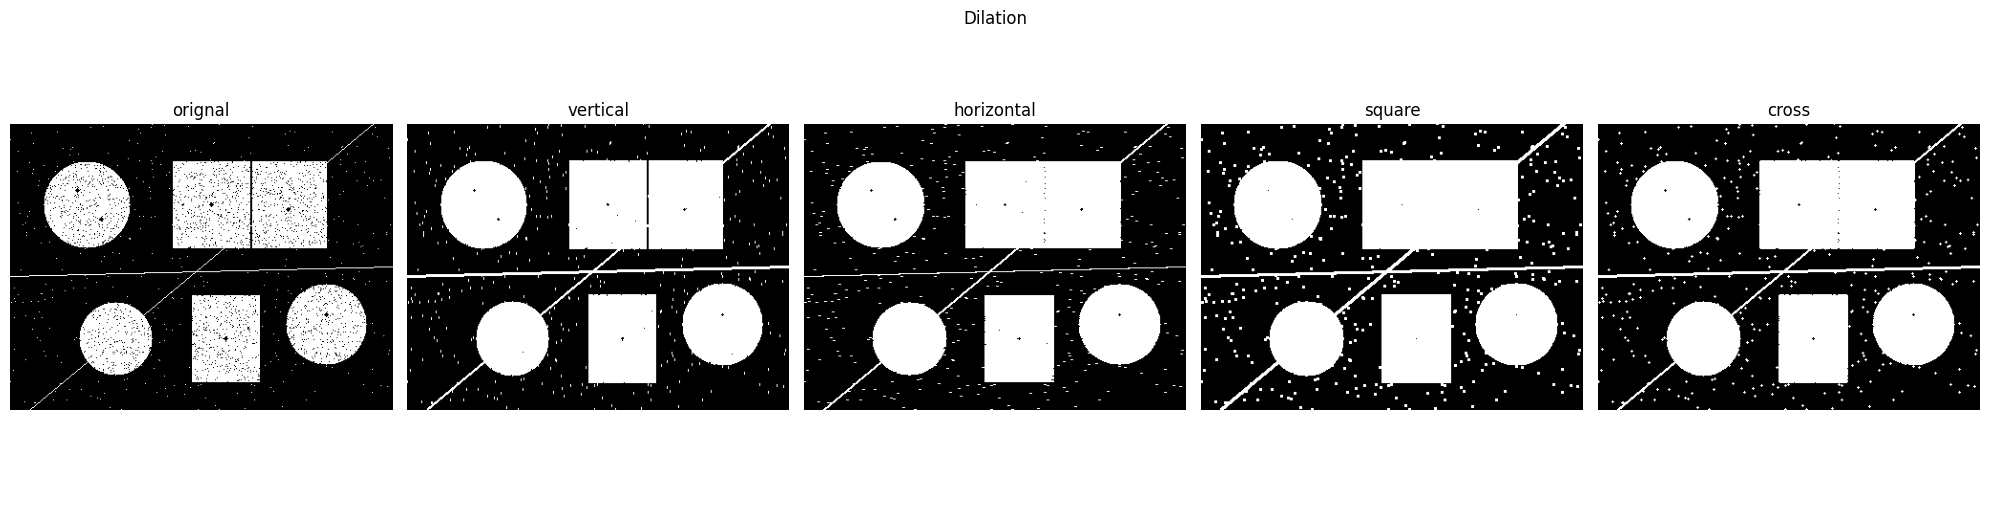

In [ ]:
crop_bin = img_bin

crop_vertical = cv.dilate(crop_bin, kernel_vertical, iterations=1)
crop_horizontal = cv.dilate(crop_bin, kernel_horizontal, iterations=1)
crop_square = cv.dilate(crop_bin, kernel_square, iterations=1)
crop_cross = cv.dilate(crop_bin, kernel_cross, iterations=1)

titles = ['orignal', 'vertical', 'horizontal', 'square', 'cross']
images = [crop_bin, crop_vertical, crop_horizontal, crop_square, crop_cross]

plt.figure(figsize=(20, 5))
plt.title('Dilation')
plt.axis('off')
for i in range(5):
  plt.subplot(1, 5, i+1)
  plt.imshow(images[i], cmap='gray')
  plt.title(titles[i])
  plt.axis('off')
plt.tight_layout()
plt.show()

- 흰 영역이 확장되면서 도형 안의 검은 점 노이즈가 대부분 메워짐
- 반대로 배경의 흰 점 노이즈와 얇은 선도 함께 커져서 배경 노이즈 제거에는 쓸 수 없음
- 노이즈가 구조 요소 모양대로 커졌다. vertical은 세로 막대, horizontal은 가로 막대, square는 네모, cross는 + 모양이다.
- 두 사각형 사이 세로 틈은 square에서 완전히, horizontal과 cross에서 대부분 메워졌고, 좌우로 퍼지지 않는 vertical에서는 그대로 남음.

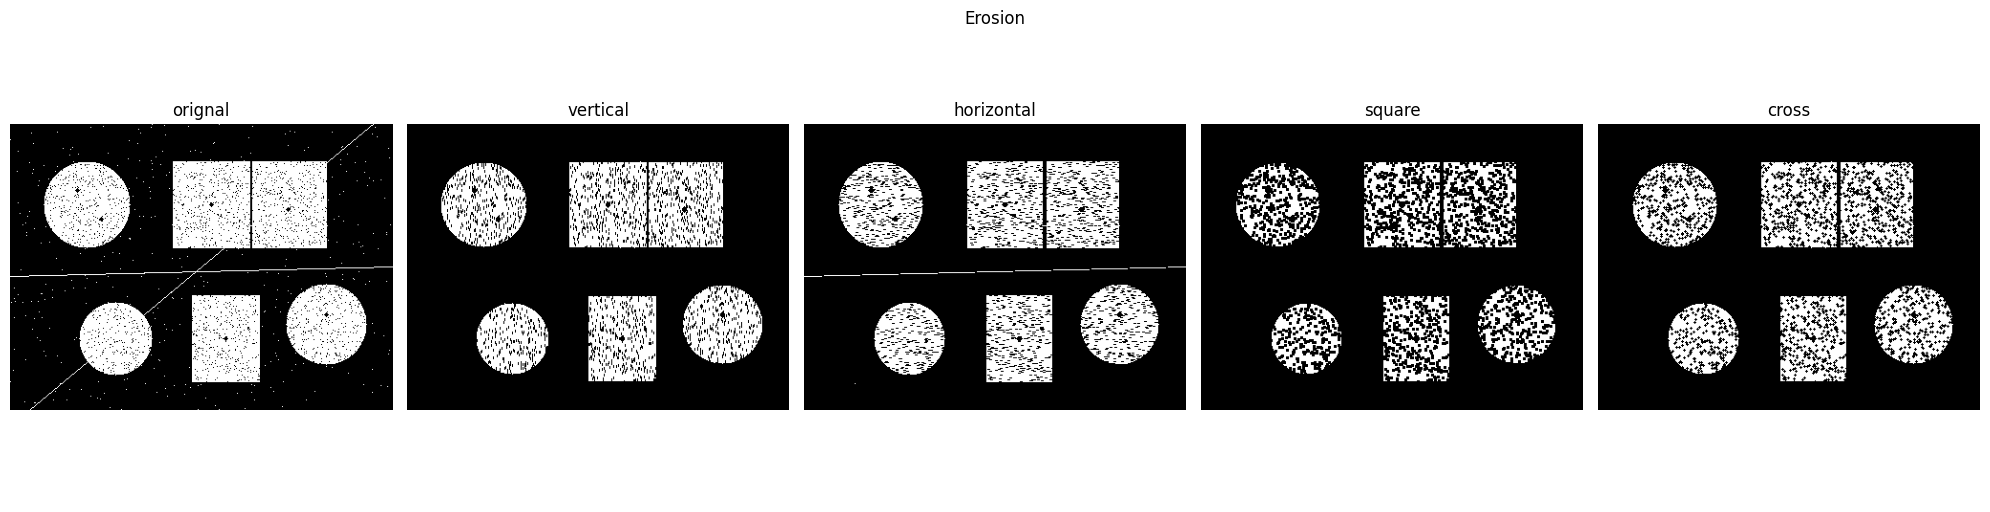

In [ ]:
crop_bin = img_bin

crop_vertical = cv.erode(crop_bin, kernel_vertical, iterations=1)
crop_horizontal = cv.erode(crop_bin, kernel_horizontal, iterations=1)
crop_square = cv.erode(crop_bin, kernel_square, iterations=1)
crop_cross = cv.erode(crop_bin, kernel_cross, iterations=1)

titles = ['orignal', 'vertical', 'horizontal', 'square', 'cross']
images = [crop_bin, crop_vertical, crop_horizontal, crop_square, crop_cross]

plt.figure(figsize=(20, 5))
plt.title('Erosion')
plt.axis('off')
for i in range(5):
  plt.subplot(1, 5, i+1)
  plt.imshow(images[i], cmap='gray')
  plt.title(titles[i])
  plt.axis('off')
plt.tight_layout()
plt.show()

- 흰 영역이 축소되면서 배경의 흰 점 노이즈가 거의 모두 사라짐.
- 반대로 도형 안의 검은 구멍은 커짐.
- horizontal 구조 요소에서는 가로선이 남음. 선과 구조 요소의 방향이 같아 선 위의 픽셀이 구조 요소 안에서 모두 1로 맞기 때문. 다른 구조 요소에서는 선이 지워짐
- 구조 요소가 클수록(square) 가장 많이 깎임.

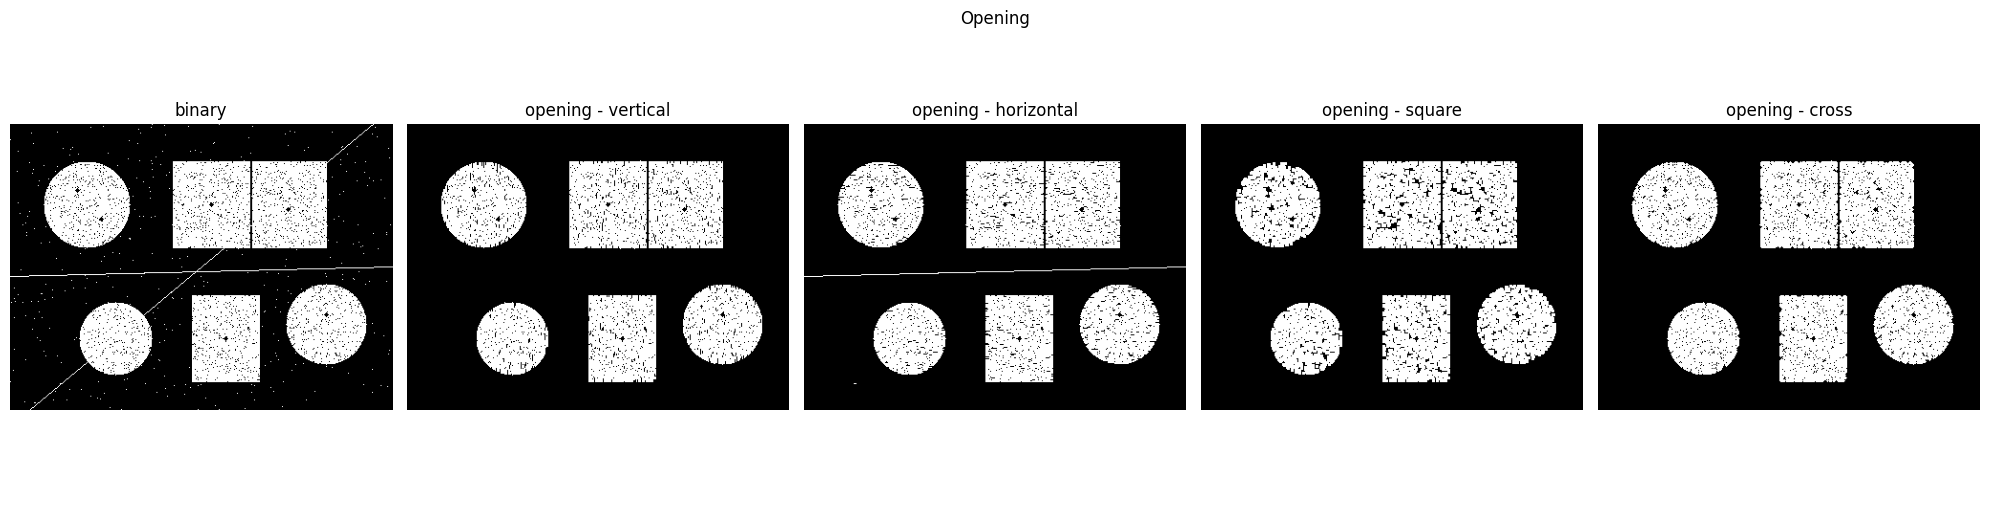

True


In [ ]:
kernels = {'vertical': kernel_vertical, 'horizontal': kernel_horizontal,
           'square': kernel_square, 'cross': kernel_cross}

titles, images = ['binary'], [img_bin]
for name, k in kernels.items():
    eroded = cv.erode(img_bin, k, iterations=1)
    opened = cv.dilate(eroded, k, iterations=1)
    titles.append('opening - ' + name)
    images.append(opened)

plt.figure(figsize=(20, 5))
plt.title('Opening')
plt.axis('off')
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

# 내장 함수와 결과 비교
print(np.array_equal(images[3], cv.morphologyEx(img_bin, cv.MORPH_OPEN, kernel_square)))

- 침식으로 배경의 흰 점 노이즈와 얇은 선을 지운 뒤, 팽창으로 도형 크기를 되돌림 -> **노이즈는 사라지고 도형 크기는 거의 유지**
- Erosion만 적용한 결과보다 도형이 덜 망가짐
- 다만 도형 안의 검은 구멍은 그대로 남아있음

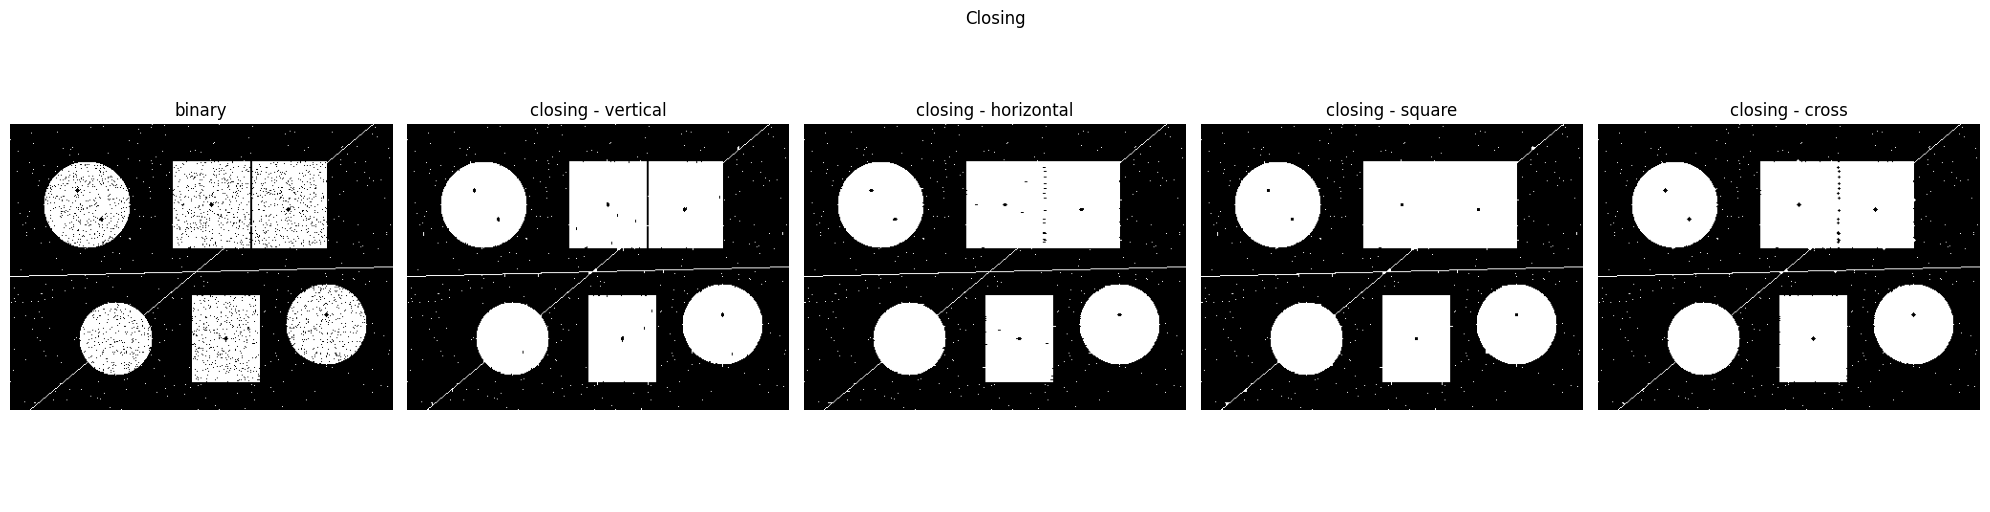

True


In [ ]:
titles, images = ['binary'], [img_bin]
for name, k in kernels.items():
    dilated = cv.dilate(img_bin, k, iterations=1)
    closed  = cv.erode(dilated, k, iterations=1)
    titles.append('closing - ' + name)
    images.append(closed)

plt.figure(figsize=(20, 5))
plt.title('Closing')
plt.axis('off')
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

print(np.array_equal(images[3], cv.morphologyEx(img_bin, cv.MORPH_CLOSE, kernel_square)))

- 팽창으로 도형 안의 검은 점과 구멍을 메운 뒤, 침식으로 도형 크기를 되돌림 ->  **빈틈은 채워지고 도형 크기는 거의 유지**.
- 두 사각형 사이 틈은 square에서 완전히 이어졌고, horizontal과 cross에서는 점선처럼 남았으며, vertical에서는 그대로 남아있음.
- 일부러 넣은 지름 5px 구멍은 3×3 구조 요소보다 커서 메워지지 않음. 구멍이 구조 요소보다 크면 closing으로 채울 수 없음.
- 배경의 흰 점 노이즈와 선은 남음. Opening과 정확히 반대 결과

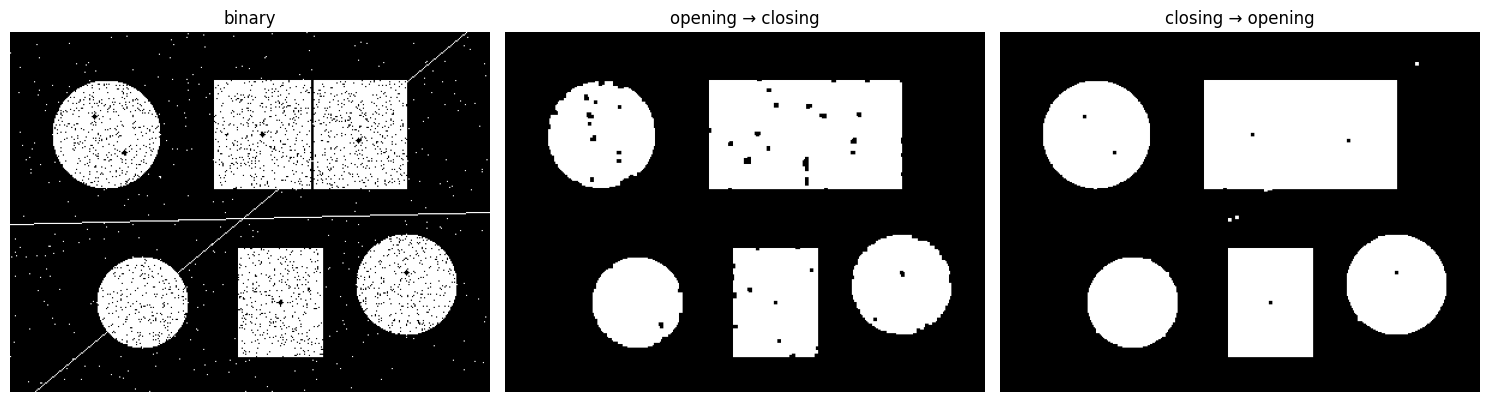

In [ ]:
def opening(x, k): return cv.dilate(cv.erode(x, k), k)
def closing(x, k): return cv.erode(cv.dilate(x, k), k)

titles = ['binary', 'opening → closing', 'closing → opening']
images = [img_bin,
          closing(opening(img_bin, kernel_square), kernel_square),
          opening(closing(img_bin, kernel_square), kernel_square)]

plt.figure(figsize=(15, 5))
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

- **Opening → Closing**: 먼저 침식 단계에서 도형 안 구멍이 커져, 이후 closing으로도 다 메우지 못함
- **Closing → Opening**: 먼저 도형 안 구멍을 메우고, 그다음 배경 노이즈와 선을 지움

- 같은 연산이라도 순서에 따라 결과가 달라짐. 이 이미지처럼 도형 안 노이즈가 많을 때는 closing을 먼저 적용하는 것이 나음!

>  결과는 구조 요소의 모양과 크기, 그리고 연산 순서에 따라 달라지므로, 처리할 노이즈의 종류에 맞춰 골라야 한다.